Nama: Johansen Tan
NIM: 2702241710

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('imbalanced_cleaned.csv')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  2000 non-null   int64 
 1   content     2000 non-null   object
 2   score       2000 non-null   int64 
dtypes: int64(2), object(1)
memory usage: 47.0+ KB


In [ ]:
df.head()

,Unnamed: 0,content,score
0,0,"this is a Nice app, what is the difference bet...",5
1,1,Please add the option of swiss tournament in t...,3
2,2,Put customization back on for pieces and board.,1
3,3,I think it is a great app to play chess on esp...,5
4,4,Da ROOOK!!!!!!!!,5


# 3. Cleaning and Lemmatization

In [ ]:
import re

# Non Words Cleaning
def cleaning(text):
  text = str(text)

  # Replace all except alphabets and space with spaces
  text = re.sub(r'[^a-zA-Z\s]', ' ', text)
  # Replace multiple spaces with one space and lower
  text = re.sub(r'\s+', ' ', text).strip().lower()

  return text

df['content'] = df['content'].apply(cleaning)

df.head(10)

,Unnamed: 0,content,score
0,0,this is a nice app what is the difference betw...,5
1,1,please add the option of swiss tournament in t...,3
2,2,put customization back on for pieces and board,1
3,3,i think it is a great app to play chess on esp...,5
4,4,da roook,5
5,5,everything is free of charge and i love itt un...,5
6,6,it making me rage quit,1
7,7,best app ever,5
8,8,best of the best,5
9,9,best chess app ever,5


In [ ]:
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet

nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('wordnet')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [ ]:
lemmatizer = WordNetLemmatizer()

# Part of Speech Tagging
def get_pos(treebank_tag):
  if treebank_tag.startswith('J'):
      return wordnet.ADJ
  elif treebank_tag.startswith('V'):
      return wordnet.VERB
  elif treebank_tag.startswith('N'):
      return wordnet.NOUN
  elif treebank_tag.startswith('R'):
      return wordnet.ADV
  else:
      return wordnet.NOUN

# Lemmatization
def lemmatization(text):
  tokens = nltk.word_tokenize(text)

  pos_tags = nltk.pos_tag(tokens)

  lemmatized_words = []
  for word, tag in pos_tags:
      wntag = get_pos(tag)

      lemma = lemmatizer.lemmatize(word, pos=wntag).lower()
      lemmatized_words.append(lemma)

  return " ".join(lemmatized_words)

df['content'] = df['content'].apply(lemmatization)

In [ ]:
df.head(10)

,Unnamed: 0,content,score
0,0,this be a nice app what be the difference betw...,5
1,1,please add the option of swiss tournament in t...,3
2,2,put customization back on for piece and board,1
3,3,i think it be a great app to play chess on esp...,5
4,4,da roook,5
5,5,everything be free of charge and i love itt un...,5
6,6,it make me rage quit,1
7,7,best app ever,5
8,8,best of the best,5
9,9,best chess app ever,5


# 4. Text Representation with TF IDF

In [ ]:
from sklearn.model_selection import train_test_split

X = df['content']
y = df['score']

X_train_0, X_test_0, y_train, y_test = train_test_split(
  X, y,
  test_size=0.2,
  random_state=42,
)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS

exceptions = {
    'not', 'no', 'never', 'nor', 'none', 'neither',
    'but', 'however', 'very', 'too', 'so', 'always'
}

stopwords = set(ENGLISH_STOP_WORDS) - exceptions
# frequent global words (across all scores)
stopwords.update(["app", "game", "chess", "play", "lichess", "chesscom", "com"])

vectorizer = TfidfVectorizer(
    stop_words = list(stopwords),
    ngram_range=(1,2),
    min_df=3,
    max_df=0.85
)

X_train = vectorizer.fit_transform(X_train_0)
X_test = vectorizer.transform(X_test_0)

In [ ]:
print(X_train.shape)

(1600, 1000)


In [ ]:
feature_names = vectorizer.get_feature_names_out()
print(f"Total features: {len(feature_names)}")
print(feature_names)

Total features: 1000
['aap' 'abandon' 'abandon not' 'ability' 'able' 'abort' 'absolute'
 'absolutely' 'abuse' 'accept' 'access' 'accidentally' 'account'
 'account not' 'accuracy' 'accuracy percentage' 'action' 'actively'
 'actually' 'ad' 'ad free' 'add' 'add ad' 'addict' 'ago' 'ahead' 'ai'
 'algorithm' 'allow' 'always' 'amaze' 'amazing' 'analyse' 'analysis'
 'analysis board' 'analysis feature' 'analysis free' 'analysis not'
 'analyze' 'android' 'animation' 'annoy' 'anonymous' 'anymore' 'appeal'
 'application' 'apps' 'arena' 'arrow' 'arrow mobile' 'asap' 'ask' 'auto'
 'automatically' 'available' 'avoid' 'away' 'awesome' 'awful' 'background'
 'bad' 'bad always' 'bad experience' 'bad not' 'ban' 'ban no' 'bar'
 'barely' 'base' 'basic' 'bc' 'bc not' 'beat' 'beginner' 'best' 'best but'
 'best computer' 'best free' 'best learn' 'best online' 'best phone'
 'best platform' 'best player' 'best site' 'best use' 'best ve' 'best way'
 'big' 'bit' 'black' 'blank' 'blitz' 'block' 'blunder' 'board' 'b

# 5. Model Training

## 5a. SVM

              precision    recall  f1-score   support

           1       0.64      0.62      0.63       108
           2       0.00      0.00      0.00        21
           3       0.17      0.07      0.10        27
           4       0.24      0.10      0.14        41
           5       0.71      0.90      0.79       203

    accuracy                           0.64       400
   macro avg       0.35      0.34      0.33       400
weighted avg       0.57      0.64      0.59       400



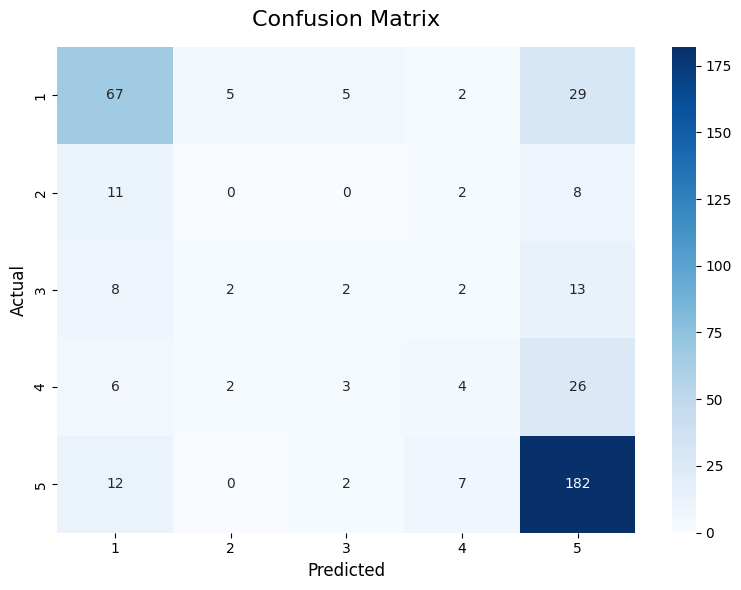

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Train Model
svm_model = LinearSVC(C=1.0, random_state=42, dual=True)
svm_model.fit(X_train, y_train)

# Test Model
y_pred = svm_model.predict(X_test)
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[1, 2, 3, 4, 5],
            yticklabels=[1, 2, 3, 4, 5])
plt.title('Confusion Matrix', fontsize=16, pad=15)
plt.xlabel('Predicted', fontsize=12)
plt.ylabel('Actual', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
errors = np.abs(y_test - y_pred)

exact_matches = np.sum(errors == 0) / len(y_test)

off_by_one = np.sum(errors <= 1) / len(y_test)

print(f"Strict Accuracy (Exact Match): {exact_matches * 100:.2f}%")
print(f"Practical Accuracy (Within 1 Star): {off_by_one * 100:.2f}%")

Strict Accuracy (Exact Match): 63.75%
Practical Accuracy (Within 1 Star): 77.75%


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ('svm', LinearSVC(random_state=42, dual=True))
])

param_grid = {
    'svm__C': [0.01, 0.1, 1, 10, 100],
    'svm__loss': ['hinge', 'squared_hinge'],

    'svm__intercept_scaling': [1, 2]
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train, y_train)
for param_name in sorted(param_grid.keys()):
    print(f"{param_name}: {grid_search.best_params_[param_name]}")

print(f"\nBest Cross-Validation Accuracy: {grid_search.best_score_ * 100:.2f}%")

best_svm = grid_search.best_estimator_
final_accuracy = best_svm.score(X_test, y_test)
print(f"Final Test Accuracy with Best Model: {final_accuracy * 100:.2f}%")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
svm__C: 0.1
svm__intercept_scaling: 1
svm__loss: squared_hinge

Best Cross-Validation Accuracy: 69.19%
Final Test Accuracy with Best Model: 67.00%


              precision    recall  f1-score   support

           1       0.62      0.72      0.67       108
           2       0.00      0.00      0.00        21
           3       0.00      0.00      0.00        27
           4       0.67      0.05      0.09        41
           5       0.69      0.93      0.79       203

    accuracy                           0.67       400
   macro avg       0.40      0.34      0.31       400
weighted avg       0.59      0.67      0.59       400



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


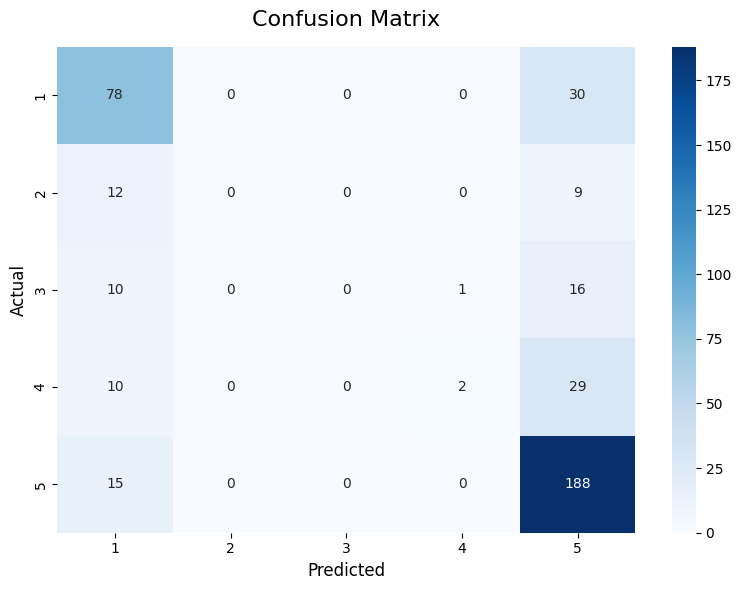

In [ ]:
# Train Model
svm_model_2 = LinearSVC(C=0.1, intercept_scaling=1, random_state=42, dual=True)
svm_model_2.fit(X_train, y_train)

# Test Model
y_pred = svm_model_2.predict(X_test)
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[1, 2, 3, 4, 5],
            yticklabels=[1, 2, 3, 4, 5])
plt.title('Confusion Matrix', fontsize=16, pad=15)
plt.xlabel('Predicted', fontsize=12)
plt.ylabel('Actual', fontsize=12)
plt.tight_layout()
plt.show()

## 5B. Random Forest Classifier

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

           1       0.58      0.70      0.63       108
           2       0.00      0.00      0.00        21
           3       0.00      0.00      0.00        27
           4       0.40      0.10      0.16        41
           5       0.72      0.91      0.80       203

    accuracy                           0.66       400
   macro avg       0.34      0.34      0.32       400
weighted avg       0.56      0.66      0.59       400



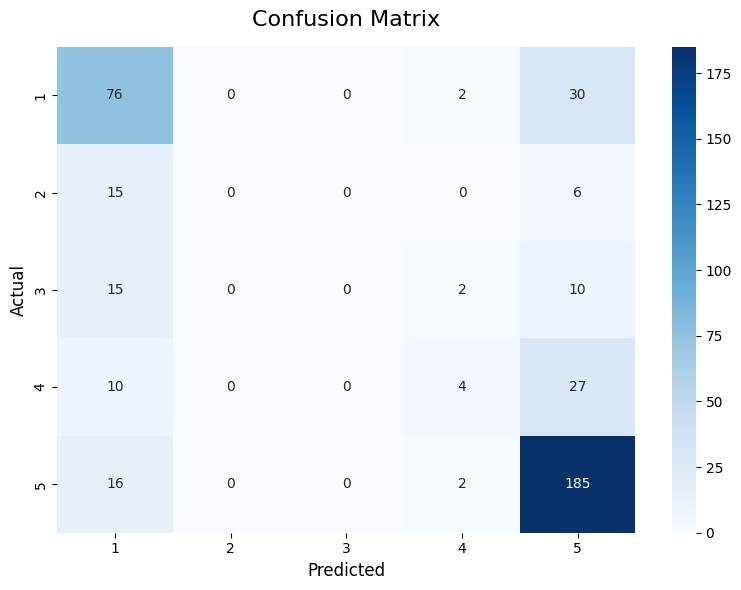

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Train Model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# Test Model
y_pred = rf_model.predict(X_test)
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[1, 2, 3, 4, 5],
            yticklabels=[1, 2, 3, 4, 5])
plt.title('Confusion Matrix', fontsize=16, pad=15)
plt.xlabel('Predicted', fontsize=12)
plt.ylabel('Actual', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
errors = np.abs(y_test - y_pred)

exact_matches = np.sum(errors == 0) / len(y_test)

off_by_one = np.sum(errors <= 1) / len(y_test)

print(f"Strict Accuracy (Exact Match): {exact_matches * 100:.2f}%")
print(f"Practical Accuracy (Within 1 Star): {off_by_one * 100:.2f}%")

Strict Accuracy (Exact Match): 66.25%
Practical Accuracy (Within 1 Star): 77.75%


In [ ]:
pipeline = Pipeline([
    ('rf', RandomForestClassifier(random_state=42, n_jobs=-1))
])

param_grid = {
    'rf__n_estimators': [50, 100],
    'rf__max_depth': [None, 50, 100],
    'rf__min_samples_split': [2, 5],
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train, y_train)
for param_name in sorted(param_grid.keys()):
    print(f"{param_name}: {grid_search.best_params_[param_name]}")

print(f"\nBest Cross-Validation Accuracy: {grid_search.best_score_ * 100:.2f}%")

best_rf = grid_search.best_estimator_
final_accuracy = best_rf.score(X_test, y_test)
print(f"Final Test Accuracy with Best Model: {final_accuracy * 100:.2f}%")

Fitting 5 folds for each of 12 candidates, totalling 60 fits
rf__max_depth: None
rf__min_samples_split: 5
rf__n_estimators: 50

Best Cross-Validation Accuracy: 68.25%
Final Test Accuracy with Best Model: 66.00%


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

           1       0.57      0.67      0.61       108
           2       0.00      0.00      0.00        21
           3       0.00      0.00      0.00        27
           4       0.33      0.02      0.05        41
           5       0.69      0.91      0.78       203

    accuracy                           0.65       400
   macro avg       0.32      0.32      0.29       400
weighted avg       0.53      0.65      0.57       400



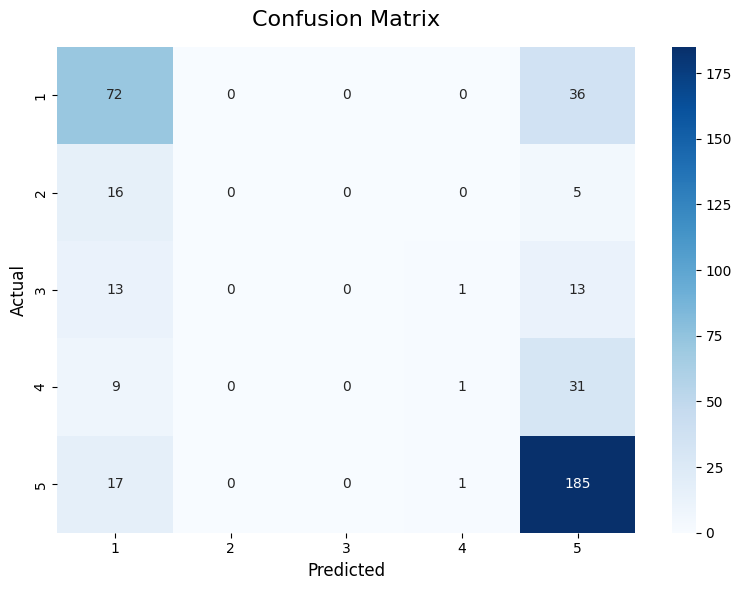

In [ ]:
# Train Model
rf_model = RandomForestClassifier(n_estimators=50, max_depth=50, min_samples_split=2, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# Test Model
y_pred = rf_model.predict(X_test)
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[1, 2, 3, 4, 5],
            yticklabels=[1, 2, 3, 4, 5])
plt.title('Confusion Matrix', fontsize=16, pad=15)
plt.xlabel('Predicted', fontsize=12)
plt.ylabel('Actual', fontsize=12)
plt.tight_layout()
plt.show()